# 15 · Portfolio Mix, Concentration, EPD-3 & Arrears Bounce (`15_portfolio_mix.py`)

How has the credit quality of our mortgage book shifted between the 2006–2008 housing peak and 2025? In this notebook we verify `15_portfolio_mix.py` read-only across its four marts: `portfolio_mix_mart` (underwriting quality over time), `concentration_mart` (HHI across states, MSAs, and sellers), `early_payment_default_mart` (EPD-3 defects within 90 days of origination), and `arrears_bounce_mart` (loans oscillating repeatedly between delinquency and current status).

<div style="background:#FFFFFF; border:1px solid #E5E7EB; border-radius:10px; padding:14px; margin:8px 0;">
<div style="font-family:Segoe UI,Arial,sans-serif; font-size:13px; font-weight:700; color:#051C2C; margin-bottom:8px;">Mix Evolution, Concentration &amp; Early-Defect Mappings</div>
<svg viewBox="0 0 920 110" width="100%" xmlns="http://www.w3.org/2000/svg">
<defs><marker id="arr" viewBox="0 0 10 10" refX="8" refY="5" markerWidth="6" markerHeight="6" orient="auto-start-reverse"><path d="M 0 1 L 10 5 L 0 9 z" fill="#2251FF"/></marker></defs>
<rect x="20" y="18" width="170" height="68" rx="8" fill="#051C2C" stroke="#051C2C" stroke-width="1.5"/>
<text x="105.0" y="46" text-anchor="middle" font-family="Segoe UI,Arial,sans-serif" font-size="12" font-weight="700" fill="#FFFFFF">Book Mix Over Time</text>
<text x="105.0" y="66" text-anchor="middle" font-family="Segoe UI,Arial,sans-serif" font-size="10.5" fill="#CBD5E1">m2.portfolio_mix_mart</text>
<line x1="194" y1="52" x2="252" y2="52" stroke="#2251FF" stroke-width="2" marker-end="url(#arr)"/>
<rect x="256" y="18" width="170" height="68" rx="8" fill="#F8FAFC" stroke="#2251FF" stroke-width="1.5"/>
<text x="341.0" y="46" text-anchor="middle" font-family="Segoe UI,Arial,sans-serif" font-size="12" font-weight="700" fill="#051C2C">HHI Concentration</text>
<text x="341.0" y="66" text-anchor="middle" font-family="Segoe UI,Arial,sans-serif" font-size="10.5" fill="#475569">m2.concentration_mart</text>
<line x1="430" y1="52" x2="488" y2="52" stroke="#2251FF" stroke-width="2" marker-end="url(#arr)"/>
<rect x="492" y="18" width="170" height="68" rx="8" fill="#F8FAFC" stroke="#2251FF" stroke-width="1.5"/>
<text x="577.0" y="46" text-anchor="middle" font-family="Segoe UI,Arial,sans-serif" font-size="12" font-weight="700" fill="#051C2C">EPD-3 Seller Defects</text>
<text x="577.0" y="66" text-anchor="middle" font-family="Segoe UI,Arial,sans-serif" font-size="10.5" fill="#475569">m2.early_payment_default_mart</text>
<line x1="666" y1="52" x2="724" y2="52" stroke="#2251FF" stroke-width="2" marker-end="url(#arr)"/>
<rect x="728" y="18" width="170" height="68" rx="8" fill="#2251FF" stroke="#2251FF" stroke-width="1.5"/>
<text x="813.0" y="46" text-anchor="middle" font-family="Segoe UI,Arial,sans-serif" font-size="12" font-weight="700" fill="#FFFFFF">Arrears Oscillation</text>
<text x="813.0" y="66" text-anchor="middle" font-family="Segoe UI,Arial,sans-serif" font-size="10.5" fill="#CBD5E1">m2.arrears_bounce_mart</text>
</svg></div>

We start by loading our read-only connection, checking HHI concentration bounds `[0, 1]`, and viewing portfolio-level credit score, LTV, DTI, and note-rate evolution across key snapshot years.

In [1]:
# Load path, DuckDB, pandas, I/O, and inline chart display utilities
# Import standard libraries to inspect saved marts read-only and render 300 dpi figures inline
import io
from pathlib import Path
import duckdb
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from IPython.display import Image, display

# Locate residential_mortgage/ root and attach module2_sample.duckdb strictly READ_ONLY
# Walk upward until reaching residential_mortgage/, then open an in-memory DuckDB connection
PACKAGE_ROOT = Path.cwd()
while PACKAGE_ROOT.name != "residential_mortgage" and PACKAGE_ROOT != PACKAGE_ROOT.parent:
    PACKAGE_ROOT = PACKAGE_ROOT.parent
if PACKAGE_ROOT.name != "residential_mortgage":
    PACKAGE_ROOT = Path(r"E:\Repos\V4_bank-credit-risk-platform\residential_mortgage")

FIXED_M2_DB = PACKAGE_ROOT / "00_data/processed/module_outputs/02_portfolio_analytics/sample/module2_sample.duckdb"
con = duckdb.connect(":memory:")
con.execute(f"ATTACH '{FIXED_M2_DB.as_posix()}' AS m2 (READ_ONLY)")

# Verify HHI concentration bounds in [0, 1] and preview latest snapshot concentration
# Check all rows of m2.concentration_mart stay bounded and inspect recent HHI by dimension
bad_hhi = con.execute("SELECT count(*) FROM m2.concentration_mart WHERE hhi < 0 OR hhi > 1.000001").fetchone()[0]
assert bad_hhi == 0, f"Found {bad_hhi} out-of-range HHI rows"
print("PASS  HHI concentration indices strictly bounded in [0, 1]")

display(con.execute("""
    SELECT snapshot_year, concentration_dim, round(hhi, 4) AS hhi, entities_count,
           round(unmapped_or_non_msa_share_pct, 2) AS unmapped_pct
    FROM m2.concentration_mart
    WHERE snapshot_year IN (2005, 2008, 2015, 2020, 2025)
    ORDER BY concentration_dim, snapshot_year
""").fetchdf())

# Summarize whole-portfolio underwriting characteristics across milestone years
# Filter m2.portfolio_mix_mart to dimension='portfolio_total' for key snapshot years
con.execute("""
    SELECT snapshot_year, loans, round(balance_upb / 1e6, 2) AS upb_M,
           round(wavg_credit_score, 1) AS wavg_fico,
           round(wavg_orig_ltv, 1) AS wavg_ltv,
           round(wavg_dti, 1) AS wavg_dti,
           round(wavg_note_rate, 2) AS wavg_rate
    FROM m2.portfolio_mix_mart
    WHERE dimension = 'portfolio_total' AND snapshot_year IN (2003, 2007, 2012, 2019, 2022, 2025)
    ORDER BY snapshot_year
""").fetchdf()

PASS  HHI concentration indices strictly bounded in [0, 1]


,snapshot_year,concentration_dim,hhi,entities_count,unmapped_pct
0,2005,msa,0.0190,313,8.82
1,2008,msa,0.0194,328,8.57
2,2015,msa,0.0204,327,7.23
3,2020,msa,0.0196,337,6.80
4,2025,msa,0.0201,356,7.12
5,2005,property_state,0.0520,53,0.00
6,2008,property_state,0.0520,53,0.00
7,2015,property_state,0.0631,53,0.00
8,2020,property_state,0.0654,52,0.00
9,2025,property_state,0.0577,53,0.00


,snapshot_year,loans,upb_M,wavg_fico,wavg_ltv,wavg_dti,wavg_rate
0,2003,2533,345.30,725.9,68.8,33.0,5.85
1,2007,2759,390.13,727.6,69.5,35.7,5.90
2,2012,3091,503.11,751.4,69.7,34.0,4.68
3,2019,3941,738.44,755.9,74.5,34.6,4.14
4,2022,4714,1019.66,759.6,71.3,34.6,3.49
5,2025,4724,1026.44,760.9,73.3,35.7,4.20


Next we examine early payment defaults (`m2.early_payment_default_mart`) by origination year and chart the 2000–2025 evolution of weighted-average credit scores and mortgage note rates.

,orig_year,eligible_loans,epd3_loans,epd3_pct
0,2005,432,20,4.63
1,2007,371,16,4.31
2,2006,322,13,4.04
3,2023,291,11,3.78
4,2021,1430,38,2.66
5,2002,1085,25,2.30
6,2001,892,20,2.24
7,2000,359,8,2.23


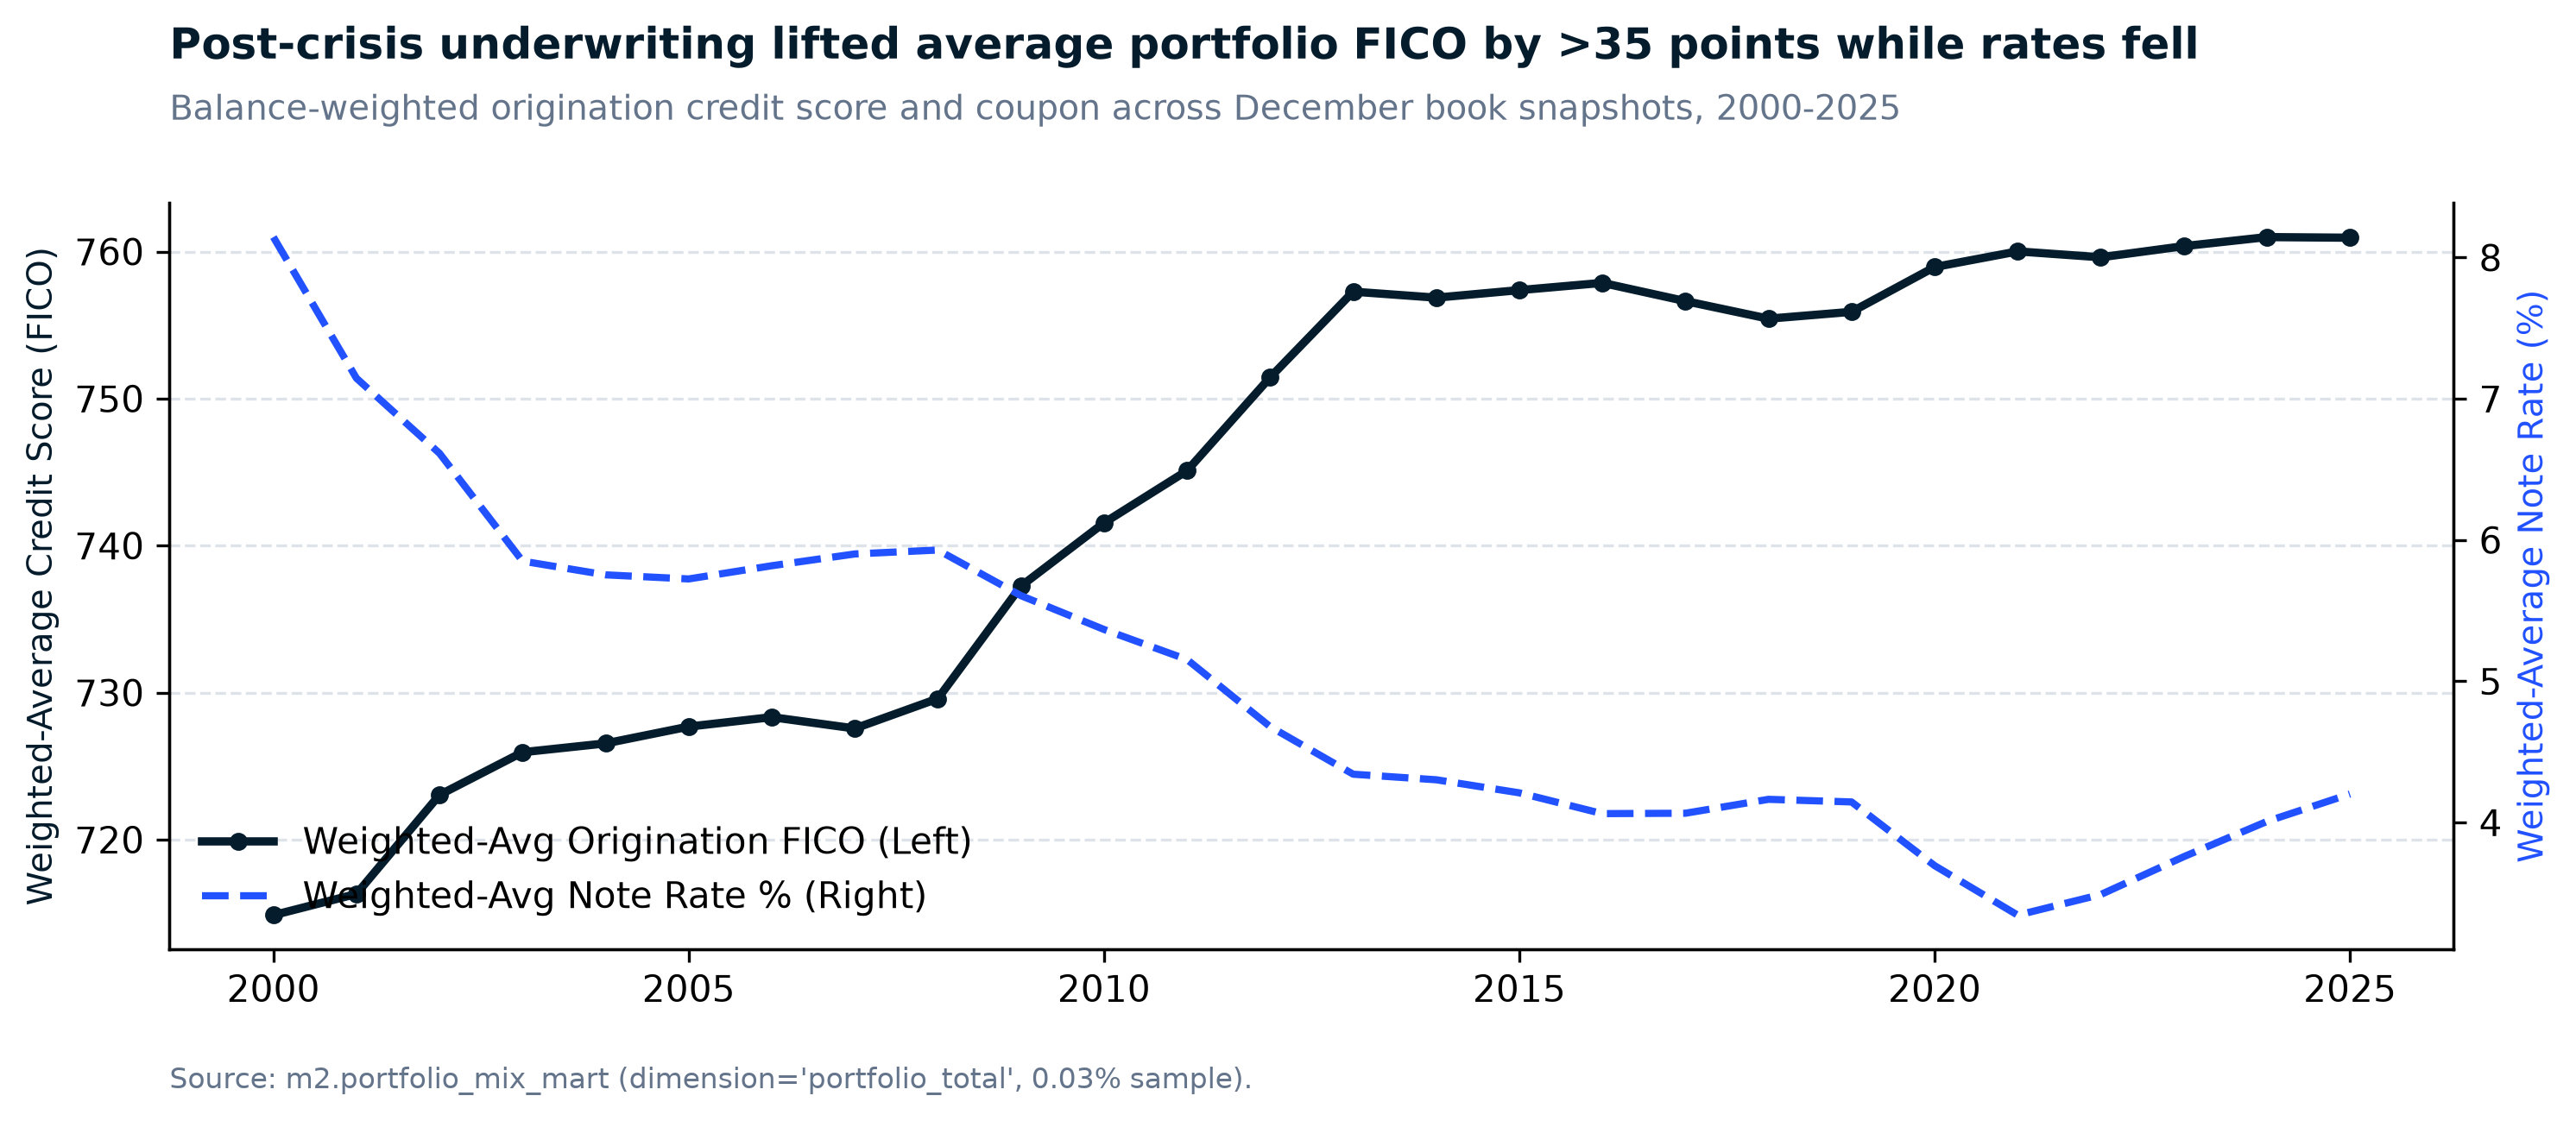

In [2]:
# Summarize origination-year EPD-3 spikes across eligible deliveries
# Aggregate eligible loans and early payment defaults by origination year cleanly
display(con.execute("""
    SELECT left(cohort_quarter, 4)::INTEGER AS orig_year,
           sum(eligible_loans)::BIGINT AS eligible_loans,
           sum(epd3_loans)::BIGINT AS epd3_loans,
           round(100.0 * sum(epd3_loans) / NULLIF(sum(eligible_loans), 0), 2) AS epd3_pct
    FROM m2.early_payment_default_mart
    GROUP BY 1
    HAVING sum(epd3_loans) > 0
    ORDER BY epd3_pct DESC
    LIMIT 8
""").fetchdf())

# Plot weighted-average portfolio credit score and note rate from 2000 to 2025
# Query m2.portfolio_mix_mart (dimension='portfolio_total') and draw twin-axis trend at 300 dpi
mix = con.execute("""
    SELECT snapshot_year, wavg_credit_score, wavg_note_rate
    FROM m2.portfolio_mix_mart
    WHERE dimension = 'portfolio_total'
    ORDER BY snapshot_year
""").fetchdf()

fig, ax1 = plt.subplots(figsize=(10.5, 4.3), dpi=300, facecolor="#FFFFFF")
ax1.set_facecolor("#FFFFFF")
ax2 = ax1.twinx()
l1 = ax1.plot(mix["snapshot_year"], mix["wavg_credit_score"], color="#051C2C", linewidth=2.3, marker="o", markersize=4, label="Weighted-Avg Origination FICO (Left)", zorder=3)
l2 = ax2.plot(mix["snapshot_year"], mix["wavg_note_rate"], color="#2251FF", linewidth=2.0, linestyle="--", label="Weighted-Avg Note Rate % (Right)", zorder=3)
ax1.grid(axis="y", linestyle="--", alpha=0.3, color="#94A3B8", zorder=0)
ax1.spines["top"].set_visible(False)
ax2.spines["top"].set_visible(False)
ax1.set_ylabel("Weighted-Average Credit Score (FICO)", fontsize=9.5, color="#051C2C")
ax2.set_ylabel("Weighted-Average Note Rate (%)", fontsize=9.5, color="#2251FF")
lines = l1 + l2
ax1.legend(lines, [l.get_label() for l in lines], frameon=False, loc="lower left")
fig.text(0.07, 0.94, "Post-crisis underwriting lifted average portfolio FICO by >35 points while rates fell", fontsize=12, fontweight="bold", color="#051C2C")
fig.text(0.07, 0.885, "Balance-weighted origination credit score and coupon across December book snapshots, 2000-2025", fontsize=9.5, color="#64748B")
fig.text(0.07, 0.015, "Source: m2.portfolio_mix_mart (dimension='portfolio_total', 0.03% sample).", fontsize=8, color="#64748B")
plt.subplots_adjust(left=0.07, right=0.91, top=0.81, bottom=0.14)
buf = io.BytesIO()
fig.savefig(buf, format="png", dpi=300, bbox_inches="tight", facecolor="#FFFFFF")
plt.close(fig)
display(Image(data=buf.getvalue()))

# Close the in-memory DuckDB connection cleanly
# Release the attached read-only sample DB handle
con.close()